 # Notebook 06 — LWC Retrieval Uncertainty (Zhu et al. 2019, Eq. 5–8)



 This notebook attaches a **1-sigma uncertainty to every retrieved LWC value**.



 Why this matters: "37 % of my LWC values are negative" is a weak statement,

 because a value of -0.05 g/m3 with an uncertainty of 0.34 g/m3 is perfectly

 consistent with zero. Socuellamos et al. (2024) make exactly this argument:

 they keep their negative values and show that ">95 % of the negative numbers

 can become positive within the uncertainty limits". Once we have sigma_LWC we

 can replace "fraction negative" with "fraction SIGNIFICANTLY negative", which

 is a much more defensible number.



 ## The equations we implement



 Zhu Eq. (6) — random error of one reflectivity measurement, in dB:



     dZ_f = 4.343 / sqrt(dt * PRF_f * N)

            * [ lambda_f * PRF_f / (4*sqrt(pi)*sigma_w_f) + 1/SNR_f^2 + 2/SNR_f ]^(1/2)



 Zhu Eq. (5) — LWC uncertainty of ONE retrieval window:



     dq_L = sqrt(dZ_f1^2 + dZ_f2^2) / [ sqrt(2) * (kappa_f1 - kappa_f2) * dh ]



 Zhu Eq. (7) — reduction from averaging M overlapping windows:



     dq_L_final = dq_L / sqrt(M_eff)



 Zhu Eq. (8) — effective sample size, accounting for window overlap:



     M_eff = M / (1 + 2 * sum_k rho(k))



 ## IMPORTANT: a labelling error in the Zhu paper



 Zhu's text describes `dh` in Eq. (5) as "the range gate spacing (in m)".

 **That is wrong.** Hogan et al. (2005), whose equations Zhu is reproducing,

 uses `(h2 - h1)` — the separation between the two heights spanning the DWR

 gradient — and Hogan Eq. (7) states explicitly:

 *"recognising that h2 - h1 = N*delta (where delta is the range gate spacing)"*.



 Combining Zhu (5)+(6) reproduces Hogan (7) **only** if dh = N * gate_spacing.

 Checked numerically: using the gate spacing instead of the window span

 overestimates the uncertainty by exactly a factor of N.



 So in this notebook `dh` is always the **vertical span of the fitting window**

 = N_gates_in_window * gate_spacing.



 ## A caveat about the theoretical route



 Hogan's Appendix states his Eq. (6) assumes *"the radar is ... of the ordinary

 pulsed type, utilizing a square-law detector and performing linear averages

 with no spectral processing"*. Our radar is an **RPG FMCW** system, which is

 none of those things. The theoretical dZ is therefore best read as a

 **lower bound** on the true noise — what the noise would be if only receiver

 noise mattered. The gap between it and the measured noise tells us how much

 other error (range sidelobes, beam mismatch, clutter) is present.

 ---

 ## Step 0 — Imports and loading

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

sys.path.append(str(Path("../src").resolve()))


In [11]:
Processed_Dataset = "20260925_pallas_raw_P02_P07_CLARA"

In [12]:
# The base retrieval inputs, written by notebook 03.
# Contains: Ze_W, Ze_Ka, T_cloud, LWP, DWR, cloud_mask, combined_mask,
#           common_mask, alpha_W, alpha_Ka, kappa_W, kappa_Ka,
#           MeanVel_W, MeanVel_Ka
path_retrieval_input = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(path_retrieval_input)

# The retrieval OUTPUTS, written by the new export cells in notebooks 04 and 05.
# Contains: lwc_guarded, n_windows, dwr_filtered   (from 04)
#           lwc_dq, dq                             (from 05)
path_zhu_output = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")


ds_zhu = xr.open_dataset(path_zhu_output)


print("Zhu output variables:", list(ds_zhu.data_vars))



Zhu output variables: ['lwc_guarded', 'n_windows', 'dwr_filtered', 'm_eff', 'derivative_guarded', 'n_used']


In [13]:
# Pull out the pieces we will use repeatedly, with explicit names.
# `.values` converts an xarray DataArray into a plain NumPy array. We do this
# where we want fast arithmetic and do not need the coordinate labels.

mask_retrieval = ds_retrieval["common_mask"]          # True = gate used in retrieval
dwr_filtered = ds_zhu["dwr_filtered"]                 # 30 s averaged + despiked DWR
lwc_zhu = ds_zhu["lwc_guarded"]                       # LWC from the Zhu retrieval
n_windows_zhu = ds_zhu["n_windows"]                   # how many windows hit each gate

kappa_W = ds_retrieval["kappa_W"]
kappa_Ka = ds_retrieval["kappa_Ka"]

# Gate spacing in kilometres.
# `.diff("range")` gives the difference between consecutive range values.
# We take the mean because the spacing can vary slightly between chirps.
TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)


r = target["range"].values.astype(float)      # the grid the retrieval ran on
sp = np.round(np.diff(r), 1)

vals, counts = np.unique(sp, return_counts=True)
print(f"grid: {r[0]:.0f}-{r[-1]:.0f} m, {len(r)} gates")
for v, c in zip(vals, counts):
    print(f"  spacing {v:5.1f} m : {c:3d} intervals")

gate_spacing_m = float(vals[np.argmax(counts)])   # the mode, not the mean/median
gate_spacing_km = gate_spacing_m / 1000.0
uniform = len(vals) == 1

print(f"\ngate spacing = {gate_spacing_m:.1f} m"
      f"{'' if uniform else '   <-- GRID NOT UNIFORM'}")


grid: 104-3986 m, 237 gates
  spacing   9.0 m :   1 intervals
  spacing  13.5 m : 133 intervals
  spacing  14.9 m :  73 intervals
  spacing  34.1 m :  28 intervals
  spacing  35.2 m :   1 intervals

gate spacing = 13.5 m   <-- GRID NOT UNIFORM


## Testing effect of different Guarded retrieval thresholds

In [14]:
import numpy as np, xarray as xr
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu

TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_filtered)
to_grid = lambda a: TR(a).reindex_like(target)
mask45  = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)

DKAPPA = to_grid(ds_retrieval["kappa_W"]  - ds_retrieval["kappa_Ka"])
DALPHA = to_grid(ds_retrieval["alpha_W"]  - ds_retrieval["alpha_Ka"])
dk = float(DKAPPA.where(mask45).median())
da = float(DALPHA.where(mask45).median())
dr = float(np.median(np.diff(target["range"].values)))
dz_gate = np.gradient(target["range"].values)   # local gate spacing for the LWP integral

OFF_DDWR, OFF_STD = 1e6, 1e6          # "guard disabled"
DDWR_VALUES = [1e6, 100.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0]
STD_VALUES  = [1e6,  10.0, 5.0, 2.0, 1.5, 1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]

print(f"dkappa {dk:.2f} | dalpha {da:.2f} | gate {dr:.1f} m\n")
print("max_ddwr_dh -> LWC window it accepts:")
for G in DDWR_VALUES[1:]:
    print(f"  {G:7.2f} dB/km : {(-0.5*G-da)/dk:+7.2f} .. {(0.5*G-da)/dk:+6.2f}"
          f"   (centre {-da/dk:+.2f}, NOT zero)")

PAD_BOTTOM, PAD_TOP = 2, 1      # your chosen pads; (0, 0) = no pads
N_WINDOW = 13                   # set to 9 if you go with N = 9

def run(ddwr, wstd, pad_b=PAD_BOTTOM, pad_t=PAD_TOP):
    lwc, ddw, meff, nwin, nused = retrieve_lwc_zhu(
        dwr=target,
        kappa_w=to_grid(ds_retrieval["kappa_W"]),
        kappa_ka=to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w=to_grid(ds_retrieval["alpha_W"]),
        alpha_ka=to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask=mask45,
        N_default=N_WINDOW, min_cloud_gates=3,
        max_ddwr_dh=ddwr, max_window_std=wstd,
        edge_pad_bottom=pad_b, edge_pad_top=pad_t)
    return xr.Dataset({"lwc": lwc, "dDWR_dh": ddw,
                       "n_windows": nwin, "N_used": nused})

sweep_ddwr = {}
print("\nsweeping max_ddwr_dh (max_window_std OFF):")
for G in DDWR_VALUES:
    sweep_ddwr[G] = run(G, OFF_STD)
    print(f"  {G:9.2f}: {int(np.isfinite(sweep_ddwr[G]['lwc'].values).sum())} gates")

sweep_std = {}
print("\nsweeping max_window_std (max_ddwr_dh OFF):")
for S in STD_VALUES:
    sweep_std[S] = run(OFF_DDWR, S)
    print(f"  {S:9.2f}: {int(np.isfinite(sweep_std[S]['lwc'].values).sum())} gates")

dkappa 3.66 | dalpha 0.31 | gate 13.5 m

max_ddwr_dh -> LWC window it accepts:
   100.00 dB/km :  -13.75 .. +13.58   (centre -0.09, NOT zero)
    80.00 dB/km :  -11.02 .. +10.85   (centre -0.09, NOT zero)
    70.00 dB/km :   -9.65 ..  +9.48   (centre -0.09, NOT zero)
    60.00 dB/km :   -8.29 ..  +8.12   (centre -0.09, NOT zero)
    50.00 dB/km :   -6.92 ..  +6.75   (centre -0.09, NOT zero)
    40.00 dB/km :   -5.55 ..  +5.38   (centre -0.09, NOT zero)
    30.00 dB/km :   -4.19 ..  +4.02   (centre -0.09, NOT zero)
    20.00 dB/km :   -2.82 ..  +2.65   (centre -0.09, NOT zero)
    10.00 dB/km :   -1.45 ..  +1.28   (centre -0.09, NOT zero)

sweeping max_ddwr_dh (max_window_std OFF):
  1000000.00: 459028 gates
     100.00: 458987 gates
      80.00: 458959 gates
      70.00: 458943 gates
      60.00: 458916 gates
      50.00: 458863 gates
      40.00: 458744 gates
      30.00: 458622 gates
      20.00: 458157 gates
      10.00: 449910 gates

sweeping max_window_std (max_ddwr_dh OFF):
  100


=== max_ddwr_dh (dB/km) ===   [other guard disabled]
max_ddwr_dh    gates  keep%  median    mean    std    <0  |L|>2 |  LWPbias%  LWPrmse  corr      n
           off   459028  100.0   0.287   0.233  0.564   19%   0.5% |       1.5     63.3  0.48  17065
        100.00   458987  100.0   0.286   0.236  0.526   19%   0.4% |       1.6     55.3  0.52  17065
         80.00   458959  100.0   0.286   0.237  0.514   19%   0.4% |       1.6     52.7  0.54  17065
         70.00   458943  100.0   0.286   0.238  0.507   19%   0.4% |       1.6     50.9  0.55  17065
         60.00   458916  100.0   0.286   0.239  0.500   19%   0.4% |       1.6     49.4  0.57  17065
         50.00   458863  100.0   0.286   0.240  0.488   19%   0.4% |       1.7     46.8  0.59  17065
         40.00   458744   99.9   0.286   0.243  0.474   19%   0.3% |       1.9     44.0  0.61  17065
         30.00   458622   99.9   0.286   0.245  0.462   18%   0.2% |       2.0     41.9  0.64  17065
         20.00   458157   99.8   0.286  

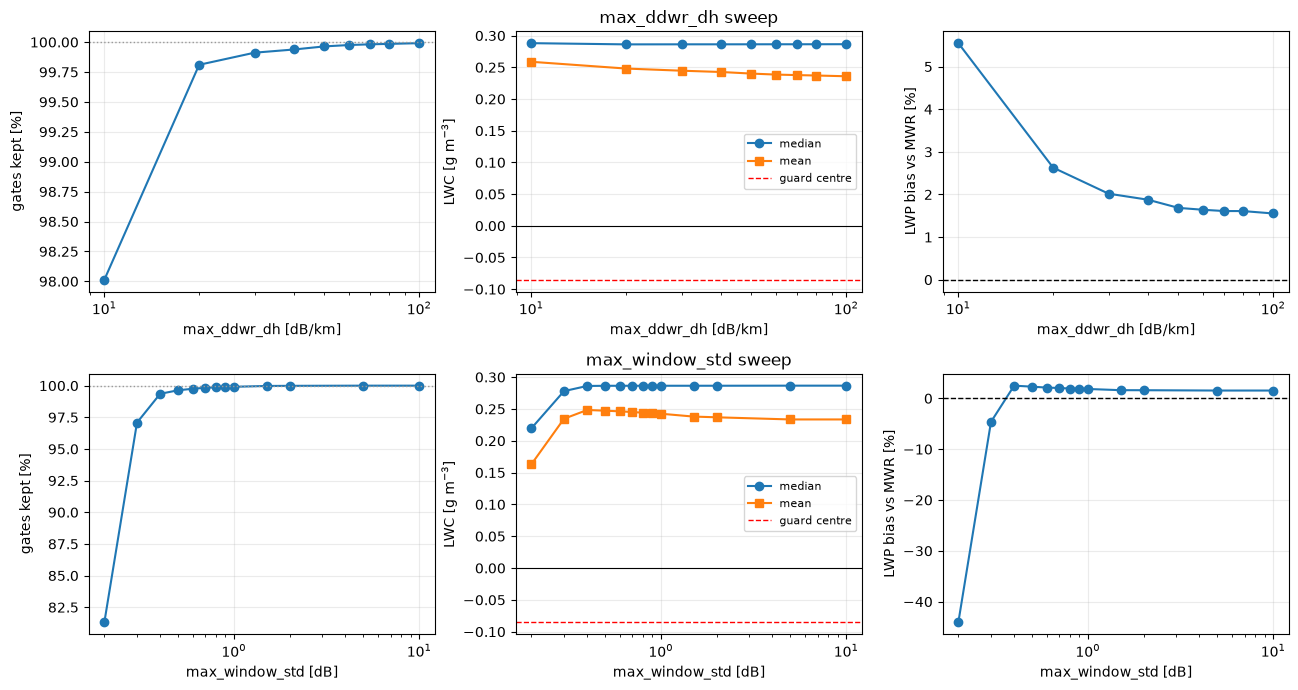

In [15]:
import matplotlib.pyplot as plt

lwp_mwr = ds_retrieval["LWP"].values

def diagnose(sweep, values, name, unit):
    base_n = int(np.isfinite(sweep[values[0]]["lwc"].values).sum())
    rows = []
    for x in values:
        L = sweep[x]["lwc"].where(mask45).values
        v = L[np.isfinite(L)]

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz_gate, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
        if ok.sum() > 30:
            rel  = 100*(lwp_r[ok]-lwp_mwr[ok])/lwp_mwr[ok]
            bias, rmse = np.median(rel), np.sqrt(np.mean((lwp_r[ok]-lwp_mwr[ok])**2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        rows.append(dict(x=x, gates=v.size, keep=100*v.size/base_n,
                         med=np.median(v), mean=v.mean(), std=v.std(),
                         neg=(v < 0).mean(), big=(np.abs(v) > 2).mean(),
                         bias=bias, rmse=rmse, corr=corr, n=int(ok.sum())))

    print(f"\n=== {name} ({unit}) ===   [other guard disabled]")
    print(f"{name:>11}{'gates':>9}{'keep%':>7}{'median':>8}{'mean':>8}{'std':>7}"
          f"{'<0':>6}{'|L|>2':>7} | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'n':>7}")
    for r_ in rows:
        lbl = "off" if r_['x'] > 1e5 else f"{r_['x']:.2f}"
        print(f"{lbl:>14}{r_['gates']:>9}{r_['keep']:>7.1f}{r_['med']:>8.3f}"
              f"{r_['mean']:>8.3f}{r_['std']:>7.3f}{r_['neg']:>6.0%}"
              f"{r_['big']:>7.1%} | {r_['bias']:>9.1f}{r_['rmse']:>9.1f}"
              f"{r_['corr']:>6.2f}{r_['n']:>7}")
    return rows


rows_g = diagnose(sweep_ddwr, DDWR_VALUES, "max_ddwr_dh", "dB/km")
rows_s = diagnose(sweep_std,  STD_VALUES,  "max_window_std", "dB")


def panel(axrow, rows, label):
    xs = [r_['x'] for r_ in rows[1:]]                 # drop the "off" point
    axrow[0].semilogx(xs, [r_['keep'] for r_ in rows[1:]], "o-")
    axrow[0].set_ylabel("gates kept [%]"); axrow[0].set_xlabel(label)
    axrow[1].semilogx(xs, [r_['med']  for r_ in rows[1:]], "o-", label="median")
    axrow[1].semilogx(xs, [r_['mean'] for r_ in rows[1:]], "s-", label="mean")
    axrow[1].axhline(-da/dk, color="r", ls="--", lw=1, label="guard centre")
    axrow[1].axhline(0, color="k", lw=0.8)
    axrow[1].set_ylabel("LWC [g m$^{-3}$]"); axrow[1].set_xlabel(label)
    axrow[1].legend(fontsize=8)
    axrow[2].semilogx(xs, [r_['bias'] for r_ in rows[1:]], "o-")
    axrow[2].axhline(0, color="k", ls="--", lw=1)
    axrow[2].set_ylabel("LWP bias vs MWR [%]"); axrow[2].set_xlabel(label)
    for a in axrow:
        a.grid(alpha=0.25)
        a.axhline(rows[0]['keep'] if a is axrow[0] else np.nan,
                  color="0.6", ls=":", lw=1)

fig, ax = plt.subplots(2, 3, figsize=(13, 7))
panel(ax[0], rows_g, "max_ddwr_dh [dB/km]")
panel(ax[1], rows_s, "max_window_std [dB]")
ax[0][1].set_title("max_ddwr_dh sweep")
ax[1][1].set_title("max_window_std sweep")
plt.tight_layout(); plt.show()

## LWP compared to ZHU Figure 5

In [16]:
dz = xr.DataArray(np.gradient(dwr_filtered["range"].values), dims="range",
                  coords={"range": dwr_filtered["range"]})
lwp_guarded_1500 = (lwc_zhu.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded_1500 = lwp_guarded_1500.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded_1500.attrs["units"] = "g m-2"

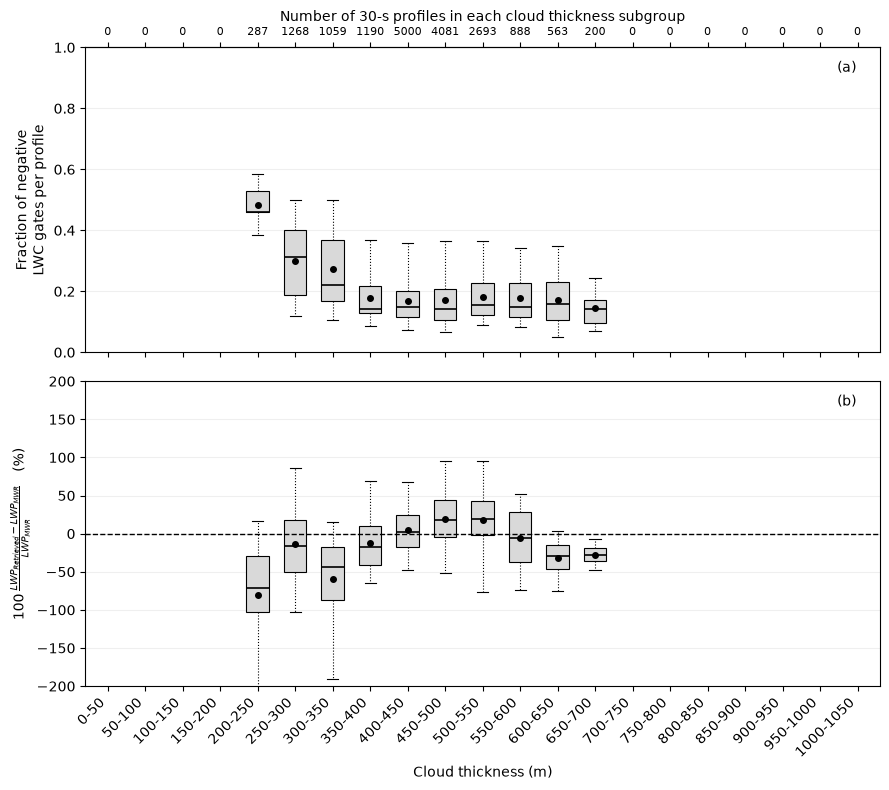

   thickness  profiles  med sigma  med rel %   n(b)
     200-250       287      0.462      -70.9    237
     250-300      1268      0.312      -15.9   1207
     300-350      1059      0.222      -43.6   1059
     350-400      1190      0.143      -17.9   1189
     400-450      5000      0.148        1.9   4995
     450-500      4081      0.143       17.7   4081
     500-550      2693      0.156       19.5   2693
     550-600       888      0.147       -6.2    888
     600-650       563      0.158      -28.8    563
     650-700       200      0.143      -28.0    200


In [17]:
import numpy as np, matplotlib.pyplot as plt

# ---- inputs -------------------------------------------------------------
lwp_mwr   = ds_retrieval["LWP"].values
lwp_radar = lwp_guarded_1500.values
# (a) fraction of negative LWC gates per profile

mask    = ds_retrieval["common_mask"].values
r         = target["range"].values
dr        = gate_spacing_m

LWP_MIN = 20.0        # g/m2; below this the ratio is dominated by MWR noise

# cloud geometric thickness per profile
thick = np.full(mask.shape[0], np.nan)
for t, mm in enumerate(mask):
    idx = np.flatnonzero(mm)
    if idx.size:
        thick[t] = r[idx[-1]] - r[idx[0]] + dr

# one uncertainty per profile
lwc_in   = lwc_zhu.where(ds_retrieval["common_mask"])
n_valid  = lwc_in.notnull().sum("range")
neg_prof = ((lwc_in < 0).sum("range") / n_valid.where(n_valid > 0)).values

# relative LWP difference (%)
rel = np.full(lwp_mwr.shape, np.nan)
ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_radar) & (lwp_mwr > LWP_MIN)
rel[ok] = 100.0 * (lwp_radar[ok] - lwp_mwr[ok]) / lwp_mwr[ok]

# ---- bin by thickness ---------------------------------------------------
edges  = np.arange(0, 1100, 50)
labels = [f"{edges[i]}-{edges[i+1]}" for i in range(len(edges) - 1)]
box_a, box_b, n_prof = [], [], []
for i in range(len(edges) - 1):
    sel = (thick >= edges[i]) & (thick < edges[i + 1])
    a = neg_prof[sel]; box_a.append(a[np.isfinite(a)])
    b = rel[sel];      box_b.append(b[np.isfinite(b)])
    n_prof.append(int(sel.sum()))

# ---- plot ---------------------------------------------------------------
pos = np.arange(len(labels))
kw = dict(widths=0.6, patch_artist=True, showfliers=False, whis=(5, 95),
          showmeans=True, manage_ticks=False,
          boxprops=dict(facecolor="0.85", edgecolor="k", lw=0.8),
          medianprops=dict(color="k", lw=1.2),
          whiskerprops=dict(color="k", lw=0.8, linestyle=":"),
          capprops=dict(color="k", lw=0.8),
          meanprops=dict(marker="o", markerfacecolor="k",
                         markeredgecolor="k", markersize=4))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

ka = [i for i in pos if len(box_a[i]) >= 5]
ax1.boxplot([box_a[i] for i in ka], positions=pos[ka], **kw)
ax1.set_ylabel("Fraction of negative\nLWC gates per profile")
ax1.set_ylim(0, 1)
ax1.text(0.97, 0.92, "(a)", transform=ax1.transAxes, ha="right")
ax1.grid(alpha=0.2, axis="y")

kb = [i for i in pos if len(box_b[i]) >= 5]
ax2.boxplot([box_b[i] for i in kb], positions=pos[kb], **kw)
ax2.axhline(0, color="k", ls="--", lw=1)
ax2.set_ylabel(r"$100\,\frac{LWP_{Retrieved}-LWP_{MWR}}{LWP_{MWR}}$   (%)")
ax2.set_ylim(-200, 200)
ax2.set_xlabel("Cloud thickness (m)")
ax2.text(0.97, 0.92, "(b)", transform=ax2.transAxes, ha="right")
ax2.grid(alpha=0.2, axis="y")

ax2.set_xticks(pos)
ax2.set_xticklabels(labels, rotation=45, ha="right")
ax2.set_xlim(-0.6, len(labels) - 0.4)

axt = ax1.secondary_xaxis("top")
axt.set_xticks(pos)
axt.set_xticklabels([str(n) for n in n_prof], fontsize=8)
axt.set_xlabel("Number of 30-s profiles in each cloud thickness subgroup")

plt.tight_layout()
plt.show()

# ---- the numbers behind the boxes ---------------------------------------
print(f"{'thickness':>12}{'profiles':>10}{'med sigma':>11}{'med rel %':>11}{'n(b)':>7}")
for i in pos:
    if n_prof[i] == 0:
        continue
    ma = np.median(box_a[i]) if len(box_a[i]) else np.nan
    mb = np.median(box_b[i]) if len(box_b[i]) else np.nan
    print(f"{labels[i]:>12}{n_prof[i]:>10}{ma:>11.3f}{mb:>11.1f}{len(box_b[i]):>7}")

## Adiabatic comparison

In [18]:
lwp_mwr = ds_retrieval["LWP"].values
r  = target["range"].values
dr = gate_spacing_m
mv = mask45.values

thick = np.full(mv.shape[0], np.nan)
ctop  = np.full(mv.shape[0], np.nan)
for t, mm in enumerate(mv):
    i = np.flatnonzero(mm)
    if i.size:
        thick[t] = r[i[-1]] - r[i[0]] + dr
        ctop[t]  = r[i[-1]]

print(f"{'thickness':>12}{'n':>7}{'LWP_MWR':>10}{'adiabatic':>11}{'ratio':>7}{'cldtop':>9}")
for lo in range(0, 1200, 50):
    sel = (thick >= lo) & (thick < lo+50) & np.isfinite(lwp_mwr)
    if sel.sum() < 20: continue
    H  = (lo + 25) / 1000.0
    ad = 0.5 * 2.0 * H**2 * 1000          # adiabatic LWP, g/m2
    med = np.median(lwp_mwr[sel])
    print(f"{lo:>5}-{lo+50:<6}{sel.sum():>7}{med:>10.1f}{ad:>11.1f}"
          f"{med/ad:>7.2f}{np.nanmedian(ctop[sel]):>9.0f}")

   thickness      n   LWP_MWR  adiabatic  ratio   cldtop
  200-250       287      23.4       50.6   0.46      328
  250-300      1268      32.9       75.6   0.44      358
  300-350      1059      67.4      105.6   0.64      402
  350-400      1190      77.7      140.6   0.55      477
  400-450      5000      96.5      180.6   0.53      522
  450-500      4081      97.8      225.6   0.43      566
  500-550      2693     100.6      275.6   0.37      611
  550-600       888     142.0      330.6   0.43      656
  600-650       563     162.4      390.6   0.42      716
  650-700       200     170.6      455.6   0.37      745
